In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import clickhouse_connect
import lightgbm as lgb
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
# Colonnes utilisées comme variables explicatives (toutes relatives, donc
# comparables entre symboles dont les prix diffèrent de plusieurs ordres de grandeur).
FEATURES: list[str] = ["ret_1m", "vol_rel", "range_pct"]
TARGET: str = "target_5m"
# Nombre de lignes (pas de 10 s) qui se chevauchent sur l'horizon de 5 min :
# 300 s / 10 s = 30. Sert à estimer le nombre d'observations indépendantes.
OVERLAP_ROWS: int = 30


def load_features(client: clickhouse_connect.driver.Client) -> pd.DataFrame:
    """Charge la table des features historiques depuis ClickHouse.

    Args:
        client: Client ClickHouse déjà connecté.

    Returns:
        Un DataFrame trié par (symbol, t), avec une colonne `t` en UTC et la
        colonne dérivée `vol_rel` (volatilité divisée par le prix moyen).
    """
    data: pd.DataFrame = client.query_df(
        """
        SELECT symbol, t, avg_price, price_volatility, range_pct, ret_1m, target_5m
        FROM trading.features_hist
        ORDER BY symbol, t
        """
    )
    data["t"] = pd.to_datetime(data["t"], utc=True)
    # Volatilité relative : l'écart-type brut est en dollars, donc non comparable.
    data["vol_rel"] = data["price_volatility"] / data["avg_price"]
    return data


def cut(data: pd.DataFrame, start: str, end: str) -> pd.DataFrame:
    """Extrait les lignes dont l'instant `t` est dans [start, end[ (UTC).

    Args:
        data: DataFrame contenant une colonne `t` de type datetime UTC.
        start: Date de début incluse, au format "YYYY-MM-DD".
        end: Date de fin exclue, au format "YYYY-MM-DD".

    Returns:
        Le sous-ensemble chronologique demandé.
    """
    mask = (data["t"] >= pd.Timestamp(start, tz="UTC")) & (
        data["t"] < pd.Timestamp(end, tz="UTC")
    )
    return data[mask]


client = clickhouse_connect.get_client(
    host="localhost",
    port=8123,
    username="trading_user",
    password=os.environ.get("CLICKHOUSE_PASSWORD", "changeme_dev_only"),
)
df: pd.DataFrame = load_features(client)

# Découpage chronologique avec un jour de trou entre les blocs
# (trou minimal : 5 min de cible + 1 min de feature = 6 min, donc 1 jour est large).
train: pd.DataFrame = cut(df, "2026-07-01", "2026-09-01")  # 62 jours
val: pd.DataFrame = cut(df, "2026-09-02", "2026-10-01")    # 29 jours
# Le test (2026-10-02 -> 2026-11-01) n'est PAS touché avant la fin du projet.
print(len(train), len(val))

1607004 751680


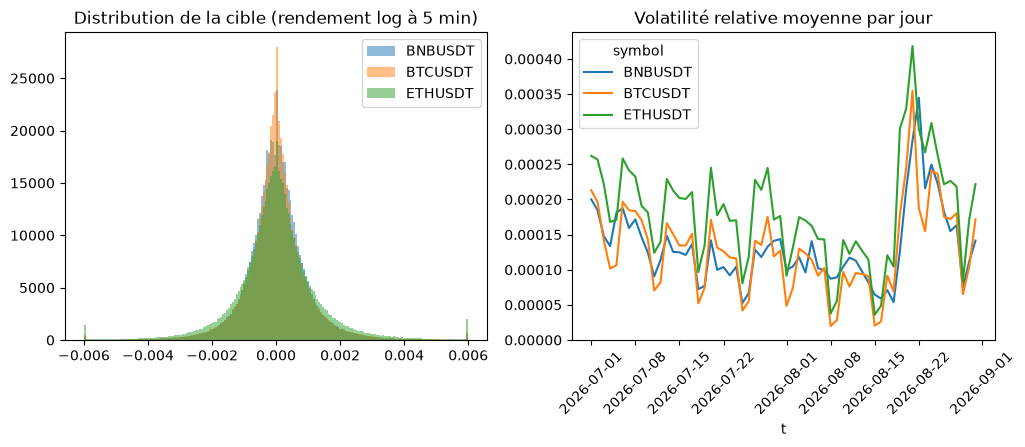

ret_1m      -0.013775
vol_rel      0.020052
range_pct    0.022424
target_5m    1.000000
Name: target_5m, dtype: float64


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Distribution de la cible par symbole ; on tronque les extrêmes pour la lisibilité.
for symbol, group in train.groupby("symbol"):
    axes[0].hist(group[TARGET].clip(-0.006, 0.006), bins=200, alpha=0.5, label=symbol)
axes[0].set_title("Distribution de la cible (rendement log à 5 min)")
axes[0].legend()

# Régime de volatilité : moyenne quotidienne de la volatilité relative.
daily_vol = train.groupby([train["t"].dt.date, "symbol"])["vol_rel"].mean().unstack()
daily_vol.plot(ax=axes[1], title="Volatilité relative moyenne par jour")
axes[1].tick_params(axis='x', labelrotation=45)
plt.show()

# Corrélation linéaire simple entre chaque feature et la cible.
print(train[FEATURES + [TARGET]].corr()[TARGET])

In [7]:
def evaluate(y: np.ndarray, pred: np.ndarray, name: str) -> dict[str, float | str]:
    """Calcule les métriques d'un modèle sur un jeu de validation ou de test.

    Args:
        y: Rendements réels (cible).
        pred: Rendements prédits par le modèle.
        name: Nom du modèle, pour l'affichage.

    Returns:
        Un dictionnaire contenant :
          - rmse : erreur quadratique moyenne du modèle ;
          - rmse_vs_zero : rapport au RMSE de la baseline "rendement nul"
            (inférieur à 1 = meilleur que la baseline) ;
          - r2_oos : gain de variance hors échantillon, `1 - rmse_vs_zero**2` ;
          - dir_acc : précision directionnelle (signe correct) ;
          - p_value : test binomial unilatéral de `dir_acc` contre le score d'un
            modèle qui prédirait toujours le signe majoritaire. Calculé sur
            le nombre effectif d'observations (lignes / 30), car les cibles se
            chevauchent. NaN si le modèle ne prédit aucun signe.
    """
    rmse: float = float(np.sqrt(np.mean((y - pred) ** 2)))
    rmse_zero: float = float(np.sqrt(np.mean(y**2)))  # baseline : rendement nul

    has_sign = pred != 0  # la baseline "zéro" n'a pas de signe à évaluer
    if has_sign.any():
        dir_acc = float(np.mean(np.sign(pred[has_sign]) == np.sign(y[has_sign])))
        n_eff = max(int(has_sign.sum() // OVERLAP_ROWS), 1)
        # Score à battre : celui d'un modèle qui prédirait toujours le signe majoritaire.
        majority = float(max((y > 0).mean(), (y <= 0).mean()))
        p_value = binomtest(
            int(round(dir_acc * n_eff)), n_eff, majority, alternative="greater"
        ).pvalue
    else:
        dir_acc, p_value = float("nan"), float("nan")

    return {
        "model": name,
        "rmse": rmse,
        "rmse_vs_zero": rmse / rmse_zero,
        "r2_oos": 1 - (rmse / rmse_zero) ** 2,
        "dir_acc": dir_acc,
        "p_value": p_value,
    }


X_train, y_train = train[FEATURES].to_numpy(), train[TARGET].to_numpy()
X_val, y_val = val[FEATURES].to_numpy(), val[TARGET].to_numpy()

# None = baseline "rendement nul" ; "mean" = baseline "moyenne d'entraînement".
models: dict = {
    "zero": None,
    "train_mean": "mean",
    "ridge": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
    # Régularisation forte (profondeur, feuilles larges, sous-échantillonnage)
    # car le signal est très bruité : un modèle libre apprendrait le bruit.
    "random_forest": RandomForestRegressor(
        n_estimators=100, max_depth=8, min_samples_leaf=500,
        max_samples=0.2, n_jobs=-1, random_state=0,
    ),
    "lightgbm": lgb.LGBMRegressor(
        n_estimators=300, learning_rate=0.03, num_leaves=15,
        min_child_samples=500, subsample=0.5, subsample_freq=1,
        colsample_bytree=0.8, random_state=0, verbose=-1,
    ),
}

results: list[dict] = []
for name, model in models.items():
    if model is None:
        predictions = np.zeros_like(y_val)
    elif isinstance(model, str):
        predictions = np.full_like(y_val, y_train.mean())
    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_val)
    results.append(evaluate(y_val, predictions, name))

pd.DataFrame(results).round(5)

,model,rmse,rmse_vs_zero,r2_oos,dir_acc,p_value
0,zero,0.0013,1.00000,0.00000,NaN,NaN
1,train_mean,0.0013,0.99997,0.00006,0.49624,0.99143
2,ridge,0.0013,0.99979,0.00042,0.49708,0.98293
3,random_forest,0.0013,0.99992,0.00015,0.49657,0.98878
4,lightgbm,0.0013,1.00012,-0.00025,0.49661,0.98840


ridge          part de prédictions > 0 : 0.779 | écart-type des prédictions : 3.51e-05
random_forest  part de prédictions > 0 : 0.959 | écart-type des prédictions : 4.50e-05
lightgbm       part de prédictions > 0 : 0.934 | écart-type des prédictions : 4.96e-05
écart-type de la cible (validation) : 1.30e-03
part de hausses réelles (validation) : 0.496


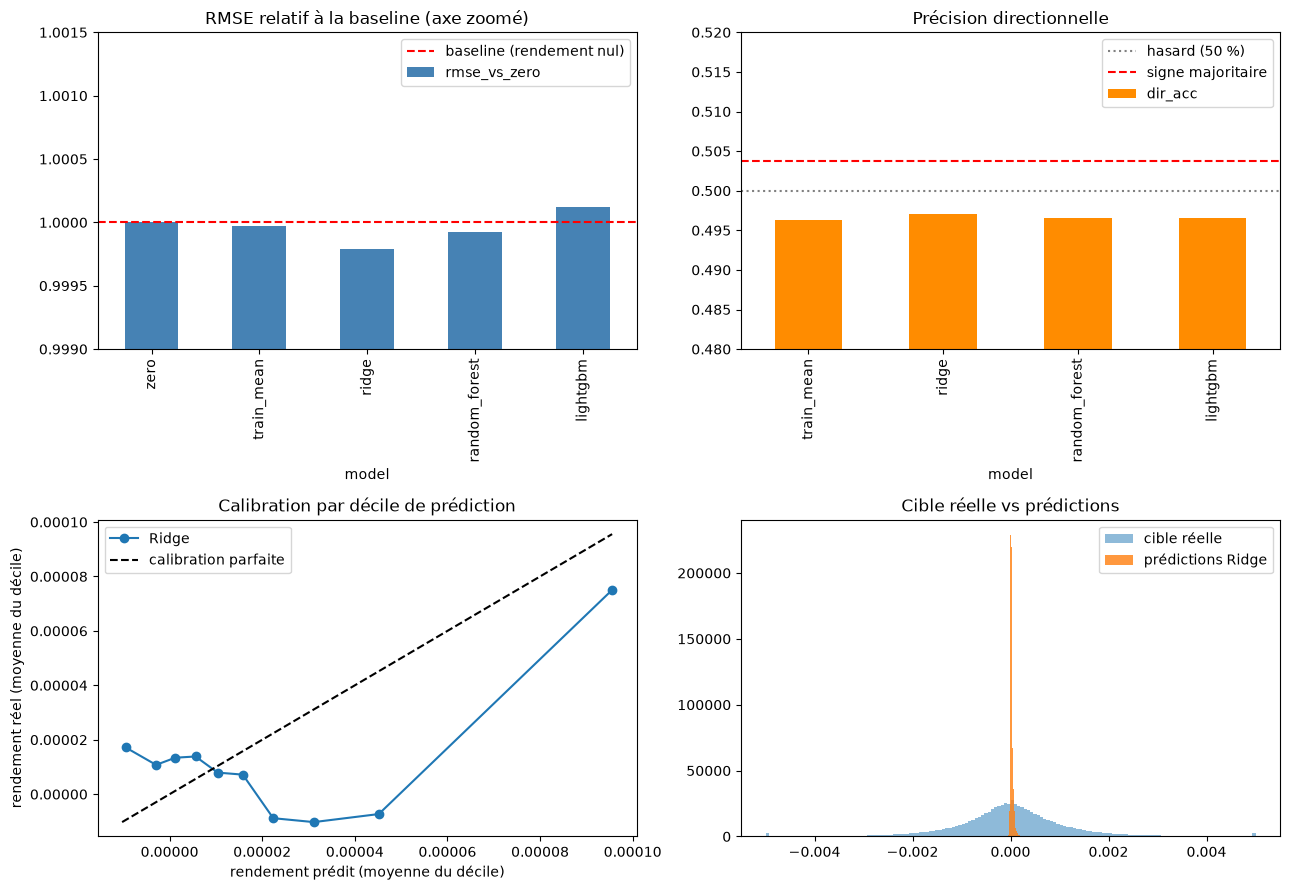

In [8]:
def positive_share(pred: np.ndarray) -> float:
    """Calcule la part de prédictions strictement positives.

    Args:
        pred: Rendements prédits par un modèle.

    Returns:
        Une valeur entre 0 et 1. Proche de 1 (ou de 0), le modèle prédit
        presque toujours le même signe : il se comporte comme une constante.
    """
    return float((pred > 0).mean())


# Prédictions de chaque modèle entraîné (les baselines sont déjà connues).
preds: dict[str, np.ndarray] = {
    name: model.predict(X_val)
    for name, model in models.items()
    if model is not None and not isinstance(model, str)
}

# Diagnostic : les modèles prédisent-ils presque toujours le même signe ?
for name, p in preds.items():
    print(f"{name:14s} part de prédictions > 0 : {positive_share(p):.3f} | "
          f"écart-type des prédictions : {p.std():.2e}")
print(f"écart-type de la cible (validation) : {y_val.std():.2e}")
print(f"part de hausses réelles (validation) : {(y_val > 0).mean():.3f}")

res = pd.DataFrame(results).set_index("model")
majority = float(max((y_val > 0).mean(), (y_val <= 0).mean()))

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. Erreur relative à la baseline : sous 1 = mieux que ne rien faire.
res["rmse_vs_zero"].plot.bar(ax=axes[0, 0], color="steelblue")
axes[0, 0].axhline(1.0, color="red", ls="--", label="baseline (rendement nul)")
axes[0, 0].set_ylim(0.9990, 1.0015)  # axe zoomé : les écarts sont minuscules
axes[0, 0].set_title("RMSE relatif à la baseline (axe zoomé)")
axes[0, 0].legend()

# 2. Précision directionnelle face au hasard et au signe majoritaire.
res["dir_acc"].dropna().plot.bar(ax=axes[0, 1], color="darkorange")
axes[0, 1].axhline(0.5, color="gray", ls=":", label="hasard (50 %)")
axes[0, 1].axhline(majority, color="red", ls="--", label="signe majoritaire")
axes[0, 1].set_ylim(0.48, 0.52)
axes[0, 1].set_title("Précision directionnelle")
axes[0, 1].legend()

# 3. Calibration (Ridge) : rendement moyen réel par décile de prédiction.
#    Un modèle utile donne une courbe croissante proche de la diagonale.
ridge_pred = preds["ridge"]
bins = pd.qcut(ridge_pred, 10, duplicates="drop")
calib = pd.DataFrame({"pred": ridge_pred, "real": y_val}).groupby(bins, observed=True).mean()
axes[1, 0].plot(calib["pred"], calib["real"], "o-", label="Ridge")
lim = [min(calib.min()), max(calib.max())]
axes[1, 0].plot(lim, lim, "k--", label="calibration parfaite")
axes[1, 0].set_xlabel("rendement prédit (moyenne du décile)")
axes[1, 0].set_ylabel("rendement réel (moyenne du décile)")
axes[1, 0].set_title("Calibration par décile de prédiction")
axes[1, 0].legend()

# 4. Dispersion : les prédictions sont-elles minuscules face à la cible ?
axes[1, 1].hist(y_val.clip(-0.005, 0.005), bins=150, alpha=0.5, label="cible réelle")
axes[1, 1].hist(ridge_pred, bins=150, alpha=0.8, label="prédictions Ridge")
axes[1, 1].set_title("Cible réelle vs prédictions")
axes[1, 1].legend()

plt.tight_layout()
plt.show()

In [9]:
from scipy.stats import spearmanr

# Cible -> nombre de lignes (pas de 10 s) qui se chevauchent sur son horizon.
HORIZONS: dict[str, int] = {"target_5m": 30, "target_60m": 360}
# Features de la volatilité : version log pour Ridge, valeur absolue du rendement passé.
FEATURES_VOL: list[str] = ["log_vol_rel", "log_range", "abs_ret_1m", "ret_1m"]


def load_features(client: clickhouse_connect.driver.Client) -> pd.DataFrame:
    """Charge les features historiques et les deux cibles depuis ClickHouse.

    Args:
        client: Client ClickHouse déjà connecté.

    Returns:
        Un DataFrame trié par (symbol, t), avec `t` en UTC et les colonnes
        dérivées `vol_rel`, `log_vol_rel`, `log_range` et `abs_ret_1m`.
    """
    data: pd.DataFrame = client.query_df(
        """
        SELECT symbol, t, avg_price, price_volatility, range_pct, ret_1m,
               target_5m, target_60m
        FROM trading.features_hist
        ORDER BY symbol, t
        """
    )
    data["t"] = pd.to_datetime(data["t"], utc=True)
    data["vol_rel"] = data["price_volatility"] / data["avg_price"]
    eps = 1e-9  # évite log(0) quand le prix est plat sur la fenêtre
    data["log_vol_rel"] = np.log(data["vol_rel"] + eps)
    data["log_range"] = np.log(data["range_pct"] + eps)
    data["abs_ret_1m"] = data["ret_1m"].abs()
    return data


def build_models() -> dict[str, object]:
    """Crée des modèles neufs (non entraînés) pour chaque expérience.

    Returns:
        Un dictionnaire nom -> modèle scikit-learn / LightGBM, fortement
        régularisé car le signal est très bruité.
    """
    return {
        "ridge": make_pipeline(StandardScaler(), Ridge(alpha=10.0)),
        "random_forest": RandomForestRegressor(
            n_estimators=100, max_depth=8, min_samples_leaf=500,
            max_samples=0.2, n_jobs=-1, random_state=0,
        ),
        "lightgbm": lgb.LGBMRegressor(
            n_estimators=300, learning_rate=0.03, num_leaves=15,
            min_child_samples=500, subsample=0.5, subsample_freq=1,
            colsample_bytree=0.8, random_state=0, verbose=-1,
        ),
    }


def split_for_target(data: pd.DataFrame, target: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Découpe en entraînement et validation, en écartant les lignes sans cible.

    Args:
        data: DataFrame complet issu de `load_features`.
        target: Nom de la colonne cible ("target_5m" ou "target_60m").

    Returns:
        Le couple (entraînement, validation). Un jour de trou sépare les blocs,
        ce qui dépasse largement 60 min de cible + 1 min de feature.
    """
    valid = data.dropna(subset=[target])
    return cut(valid, "2026-07-01", "2026-09-01"), cut(valid, "2026-09-02", "2026-10-01")


def evaluate_direction(y: np.ndarray, pred: np.ndarray, name: str,
                       overlap_rows: int) -> dict[str, float | str]:
    """Évalue un modèle sur la direction du rendement.

    Args:
        y: Rendements réels.
        pred: Rendements prédits.
        name: Nom du modèle.
        overlap_rows: Nombre de lignes dont les cibles se chevauchent
            (30 pour 5 min, 360 pour 60 min), pour estimer le N effectif.

    Returns:
        RMSE, rapport au RMSE de la baseline "rendement nul", précision
        directionnelle et p-value du test binomial unilatéral contre le signe
        majoritaire (NaN si le modèle ne prédit aucun signe).
    """
    rmse = float(np.sqrt(np.mean((y - pred) ** 2)))
    rmse_zero = float(np.sqrt(np.mean(y**2)))
    has_sign = pred != 0
    if has_sign.any():
        dir_acc = float(np.mean(np.sign(pred[has_sign]) == np.sign(y[has_sign])))
        n_eff = max(int(has_sign.sum() // overlap_rows), 1)
        majority = float(max((y > 0).mean(), (y <= 0).mean()))
        p_value = binomtest(int(round(dir_acc * n_eff)), n_eff, majority,
                            alternative="greater").pvalue
    else:
        dir_acc, p_value = float("nan"), float("nan")
    return {"model": name, "rmse_vs_zero": rmse / rmse_zero,
            "dir_acc": dir_acc, "p_value": p_value}


def run_direction(train: pd.DataFrame, val: pd.DataFrame, target: str,
                  overlap_rows: int) -> pd.DataFrame:
    """Lance l'expérience « direction » pour un horizon.

    Args:
        train: Bloc d'entraînement.
        val: Bloc de validation.
        target: Colonne cible.
        overlap_rows: Chevauchement des cibles, en lignes.

    Returns:
        Un tableau de métriques, une ligne par modèle (baselines incluses).
    """
    X_tr, y_tr = train[FEATURES].to_numpy(), train[target].to_numpy()
    X_va, y_va = val[FEATURES].to_numpy(), val[target].to_numpy()
    rows = [
        evaluate_direction(y_va, np.zeros_like(y_va), "zero", overlap_rows),
        evaluate_direction(y_va, np.full_like(y_va, y_tr.mean()), "train_mean", overlap_rows),
    ]
    for name, model in build_models().items():
        model.fit(X_tr, y_tr)
        rows.append(evaluate_direction(y_va, model.predict(X_va), name, overlap_rows))
    return pd.DataFrame(rows).set_index("model")


def daily_spearman(val: pd.DataFrame, y: np.ndarray, pred: np.ndarray) -> pd.Series:
    """Calcule la corrélation de rang (Spearman) entre prédiction et cible, jour par jour.

    Args:
        val: Bloc de validation (colonne `t` en UTC).
        y: Valeurs réelles.
        pred: Valeurs prédites.

    Returns:
        Une série indexée par jour. Une corrélation positive presque tous les
        jours est plus convaincante qu'une moyenne globale, car elle ne dépend
        pas d'un seul épisode de marché.
    """
    frame = pd.DataFrame({"day": val["t"].dt.date.to_numpy(), "y": y, "p": pred})
    return frame.groupby("day")[["y", "p"]].apply(
        lambda g: spearmanr(g["p"], g["y"]).statistic)


def run_volatility(train: pd.DataFrame, val: pd.DataFrame,
                   target: str) -> tuple[pd.DataFrame, dict[str, np.ndarray]]:
    """Lance l'expérience « volatilité » : prédire |rendement futur|.

    Les baselines sont la moyenne d'entraînement (constante) et la persistance
    (la volatilité relative actuelle, mise à l'échelle par un seul coefficient
    estimé sur l'entraînement).

    Args:
        train: Bloc d'entraînement.
        val: Bloc de validation.
        target: Colonne du rendement futur.

    Returns:
        Un couple (tableau de métriques, prédictions de chaque modèle).
        `r2_vs_mean` > 0 signifie que le modèle bat la moyenne constante.
    """
    y_tr, y_va = train[target].abs().to_numpy(), val[target].abs().to_numpy()
    X_tr, X_va = train[FEATURES_VOL].to_numpy(), val[FEATURES_VOL].to_numpy()

    mse_mean = float(np.mean((y_va - y_tr.mean()) ** 2))
    scale = y_tr.mean() / train["vol_rel"].mean()  # unique coefficient de la persistance
    preds: dict[str, np.ndarray] = {
        "train_mean": np.full_like(y_va, y_tr.mean()),
        "persistence": scale * val["vol_rel"].to_numpy(),
    }
    for name, model in build_models().items():
        model.fit(X_tr, y_tr)
        preds[name] = model.predict(X_va)

    rows = []
    for name, p in preds.items():
        rows.append({
            "model": name,
            "r2_vs_mean": 1 - float(np.mean((y_va - p) ** 2)) / mse_mean,
            "spearman": float("nan") if name == "train_mean" else float(spearmanr(p, y_va).statistic),
        })
    return pd.DataFrame(rows).set_index("model"), preds


df = load_features(client)

In [10]:
vol_results: dict[str, pd.DataFrame] = {}
vol_preds: dict[str, dict[str, np.ndarray]] = {}
vol_blocks: dict[str, pd.DataFrame] = {}

for target, overlap in HORIZONS.items():
    train_h, val_h = split_for_target(df, target)
    print(f"\n===== {target} | {len(train_h)} lignes d'entraînement, {len(val_h)} de validation =====")
    print(f"écart-type de la cible (validation) : {val_h[target].std():.4%}"
          f"  (frais aller-retour : 0,15 % à 0,20 %)")

    print("\n-- Direction --")
    print(run_direction(train_h, val_h, target, overlap).round(5))

    print("\n-- Volatilité (|rendement|) --")
    table, preds = run_volatility(train_h, val_h, target)
    print(table.round(4))
    vol_results[target], vol_preds[target], vol_blocks[target] = table, preds, val_h


===== target_5m | 1607004 lignes d'entraînement, 751680 de validation =====
écart-type de la cible (validation) : 0.1302%  (frais aller-retour : 0,15 % à 0,20 %)

-- Direction --
               rmse_vs_zero  dir_acc  p_value
model                                        
zero                1.00000      NaN      NaN
train_mean          0.99997  0.49624  0.99143
ridge               0.99979  0.49708  0.98293
random_forest       0.99992  0.49657  0.98878
lightgbm            1.00012  0.49661  0.98840

-- Volatilité (|rendement|) --
               r2_vs_mean  spearman
model                              
train_mean         0.0000       NaN
persistence       -0.1305    0.2920
ridge              0.1027    0.2888
random_forest      0.1457    0.3224
lightgbm           0.1448    0.3216

===== target_60m | 1607004 lignes d'entraînement, 751680 de validation =====
écart-type de la cible (validation) : 0.4313%  (frais aller-retour : 0,15 % à 0,20 %)

-- Direction --
               rmse_vs_zero  dir_

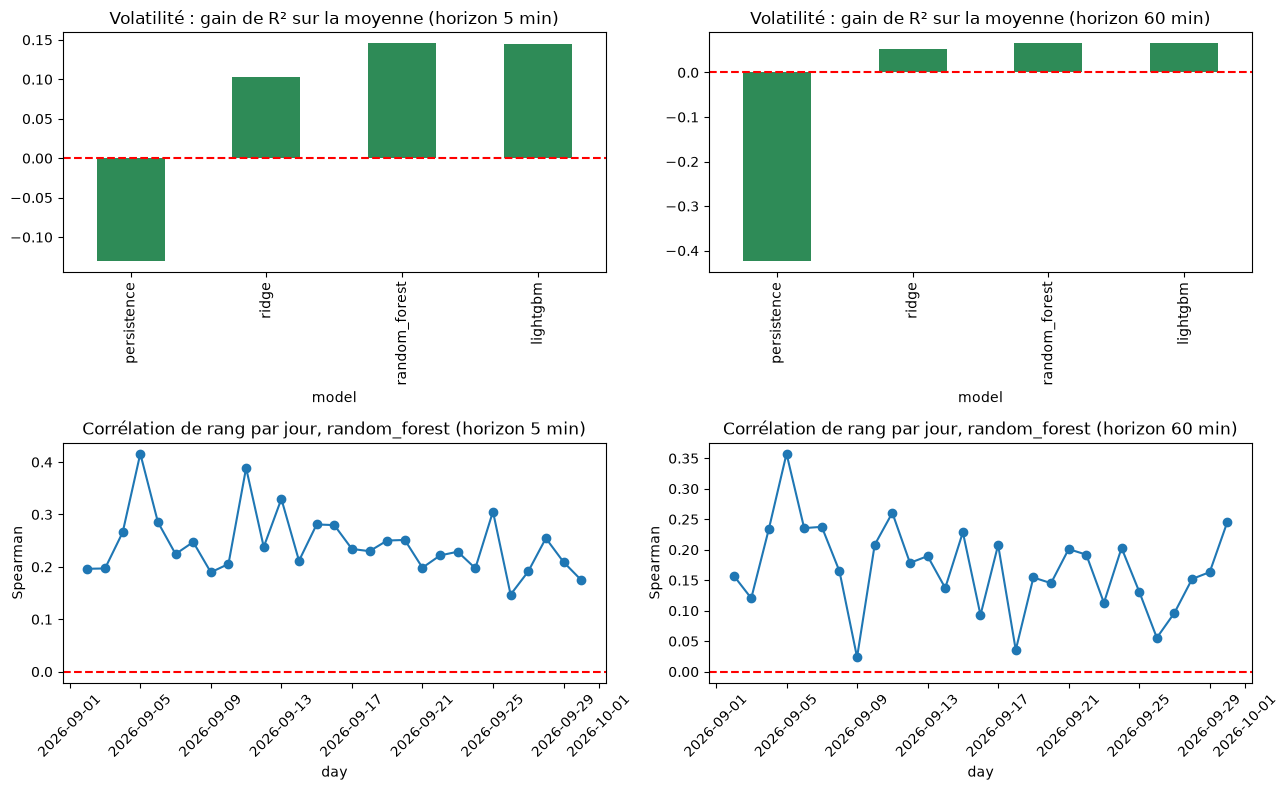

In [35]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
labels = {"target_5m": "horizon 5 min", "target_60m": "horizon 60 min"}

for i, target in enumerate(HORIZONS):
    table = vol_results[target]
    # Haut : le modèle bat-il la moyenne constante ? (0 = non, > 0 = oui)
    table["r2_vs_mean"].drop("train_mean").plot.bar(ax=axes[0, i], color="seagreen")
    axes[0, i].axhline(0, color="red", ls="--")
    axes[0, i].set_title(f"Volatilité : gain de R² sur la moyenne ({labels[target]})")

    # Bas : le signal est-il stable jour après jour ? (meilleur modèle appris)
    best = table.drop(["train_mean", "persistence"])["spearman"].idxmax()
    val_h = vol_blocks[target]
    daily = daily_spearman(val_h, val_h[target].abs().to_numpy(), vol_preds[target][best])
    daily.plot(ax=axes[1, i], marker="o")
    axes[1, i].axhline(0, color="red", ls="--")
    axes[1, i].set_title(f"Corrélation de rang par jour, {best} ({labels[target]})")
    axes[1, i].set_ylabel("Spearman")
    axes[1, i].tick_params(axis="x", labelrotation=45)

plt.tight_layout()
plt.show()

In [23]:
def add_context_features(data: pd.DataFrame) -> pd.DataFrame:
    """Ajoute l'heure (cyclique) et la volatilité moyenne des 30 dernières minutes.

    Args:
        data: DataFrame issu de `load_features`, trié par (symbol, t).

    Returns:
        Une copie, avec un index réinitialisé, contenant les colonnes
        `hour_sin`, `hour_cos` (heure UTC encodée sur un cercle, pour que
        23 h et 0 h soient voisines) et `log_vol_30m` (moyenne glissante de
        `log_vol_rel` sur 30 min, calculée symbole par symbole). Cette
        dernière vaut NaN pendant les 30 premières minutes de chaque symbole.
    """
    # Index unique et ordonné : évite tout problème d'alignement.
    out = data.sort_values(["symbol", "t"]).reset_index(drop=True)
    hour = out["t"].dt.hour + out["t"].dt.minute / 60
    out["hour_sin"] = np.sin(2 * np.pi * hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * hour / 24)

    # Fenêtre définie en TEMPS (30 min) et non en nombre de lignes ; il faut
    # 180 lignes de 10 s pour qu'elle soit complète. On calcule symbole par
    # symbole, puis on assigne par position (pas par index).
    parts: list[np.ndarray] = []
    for _, group in out.groupby("symbol", sort=False):
        rolled = (
            group.set_index("t")["log_vol_rel"]
            .rolling("30min", min_periods=180)
            .mean()
        )
        parts.append(rolled.to_numpy())
    out["log_vol_30m"] = np.concatenate(parts)
    return out

In [24]:
check = add_context_features(df)
print(check[["symbol", "t", "log_vol_rel", "log_vol_30m"]].head(3))
print(check["log_vol_30m"].isna().groupby(check["symbol"]).sum())

    symbol                         t  log_vol_rel  log_vol_30m
0  BNBUSDT 2026-07-01 00:02:00+00:00    -8.669311          NaN
1  BNBUSDT 2026-07-01 00:02:10+00:00    -9.096754          NaN
2  BNBUSDT 2026-07-01 00:02:20+00:00    -9.163361          NaN
symbol
BNBUSDT    179
BTCUSDT    179
ETHUSDT    179
Name: log_vol_30m, dtype: int64


In [25]:
SYMBOL_COLS: list[str] = ["sym_BNBUSDT", "sym_BTCUSDT", "sym_ETHUSDT"]


def add_symbol_dummies(data: pd.DataFrame) -> pd.DataFrame:
    """Ajoute le symbole encodé en variables binaires (une colonne par symbole).

    Args:
        data: DataFrame contenant une colonne `symbol`.

    Returns:
        Une copie avec les colonnes `sym_BNBUSDT`, `sym_BTCUSDT`, `sym_ETHUSDT`.
    """
    dummies = pd.get_dummies(data["symbol"], prefix="sym", dtype=float)
    return pd.concat([data, dummies], axis=1)


def run_variants(train: pd.DataFrame, val: pd.DataFrame, target: str) -> pd.DataFrame:
    """Compare un modèle groupé, groupé avec symbole, et un modèle par symbole.

    Le modèle est la forêt aléatoire. Les métriques sont calculées symbole par
    symbole, le R² étant mesuré contre la moyenne d'entraînement DU MÊME symbole.

    Args:
        train: Bloc d'entraînement (avec colonnes de contexte et du symbole).
        val: Bloc de validation.
        target: Colonne du rendement futur.

    Returns:
        Un tableau (variante x symbole) avec `r2_vs_mean` et `spearman`.
    """
    y_tr = train[target].abs().to_numpy()
    y_va = val[target].abs().to_numpy()
    cols_plain = FEATURES_VOL
    cols_sym = FEATURES_VOL + SYMBOL_COLS
    symbols = sorted(val["symbol"].unique())

    preds: dict[str, np.ndarray] = {}
    preds["pooled"] = build_models()["random_forest"].fit(
        train[cols_plain], y_tr).predict(val[cols_plain])
    preds["pooled+symbol"] = build_models()["random_forest"].fit(
        train[cols_sym], y_tr).predict(val[cols_sym])

    per_symbol = np.empty(len(val))
    for s in symbols:
        tr_m = (train["symbol"] == s).to_numpy()
        va_m = (val["symbol"] == s).to_numpy()
        model = build_models()["random_forest"].fit(train.loc[tr_m, cols_plain], y_tr[tr_m])
        per_symbol[va_m] = model.predict(val.loc[va_m, cols_plain])
    preds["per_symbol"] = per_symbol

    rows: list[dict] = []
    for name, p in preds.items():
        for s in symbols:
            tr_m = (train["symbol"] == s).to_numpy()
            va_m = (val["symbol"] == s).to_numpy()
            mse_mean = float(np.mean((y_va[va_m] - y_tr[tr_m].mean()) ** 2))
            rows.append({
                "variant": name, "symbol": s,
                "r2_vs_mean": 1 - float(np.mean((y_va[va_m] - p[va_m]) ** 2)) / mse_mean,
                "spearman": float(spearmanr(p[va_m], y_va[va_m]).statistic),
            })
    return pd.DataFrame(rows).pivot(index="variant", columns="symbol",
                                    values=["r2_vs_mean", "spearman"])


# Une seule fois : ne pas relancer cette ligne sur un df_ctx déjà enrichi.
df_ctx = add_symbol_dummies(add_context_features(df).dropna(subset=["log_vol_30m"]))

for target in HORIZONS:
    train_h, val_h = split_for_target(df_ctx, target)
    print(f"\n===== {target} =====")
    print(run_variants(train_h, val_h, target).round(3))


===== target_5m =====
              r2_vs_mean                 spearman                
symbol           BNBUSDT BTCUSDT ETHUSDT  BNBUSDT BTCUSDT ETHUSDT
variant                                                          
per_symbol         0.158   0.187   0.162    0.332   0.399   0.369
pooled             0.177   0.192   0.165    0.336   0.399   0.368
pooled+symbol      0.177   0.194   0.165    0.335   0.399   0.368

===== target_60m =====
              r2_vs_mean                 spearman                
symbol           BNBUSDT BTCUSDT ETHUSDT  BNBUSDT BTCUSDT ETHUSDT
variant                                                          
per_symbol         0.054   0.124   0.085    0.201   0.357   0.300
pooled             0.097   0.116   0.082    0.240   0.359   0.293
pooled+symbol      0.091   0.121   0.088    0.233   0.357   0.296


In [26]:
for target in HORIZONS:
    train_h, val_h = split_for_target(df_ctx, target)
    y_tr, y_va = train_h[target].abs().to_numpy(), val_h[target].abs().to_numpy()
    mse_mean = float(np.mean((y_va - y_tr.mean()) ** 2))

    # Persistance calibrée (vol_rel seul) : la baseline à battre.
    p_cal = calibrated_persistence(train_h, val_h, target)
    print(f"\n{target} | persistance calibrée : R² = "
          f"{1 - float(np.mean((y_va - p_cal) ** 2)) / mse_mean:.4f}")

    # Forêt avec les features de contexte, évaluée par symbole.
    forest = build_models()["random_forest"].fit(train_h[FEATURES_VOL], y_tr)
    pred = forest.predict(val_h[FEATURES_VOL])
    r2 = 1 - float(np.mean((y_va - pred) ** 2)) / mse_mean
    print(f"  forêt + contexte : R² = {r2:.4f}")
    vol_now = val_h["vol_rel"].to_numpy()
    for symbol, idx in val_h.groupby("symbol").indices.items():
        print(f"  {symbol}: forêt {spearmanr(pred[idx], y_va[idx]).statistic:.3f} | "
              f"persistance {spearmanr(vol_now[idx], y_va[idx]).statistic:.3f}")


target_5m | persistance calibrée : R² = 0.1187
  forêt + contexte : R² = 0.1807
  BNBUSDT: forêt 0.336 | persistance 0.241
  BTCUSDT: forêt 0.399 | persistance 0.307
  ETHUSDT: forêt 0.368 | persistance 0.282

target_60m | persistance calibrée : R² = 0.0465
  forêt + contexte : R² = 0.0996
  BNBUSDT: forêt 0.240 | persistance 0.166
  BTCUSDT: forêt 0.359 | persistance 0.248
  ETHUSDT: forêt 0.293 | persistance 0.212


In [27]:
def final_blocks(data: pd.DataFrame, target: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Construit le bloc de développement (entraînement + validation) et le bloc de test.

    Args:
        data: DataFrame enrichi (`df_ctx`), avec les colonnes de contexte.
        target: Colonne cible ("target_5m" ou "target_60m").

    Returns:
        Le couple (développement, test). Un jour de trou sépare chaque bloc,
        ce qui dépasse largement 60 min de cible + 30 min de feature.
    """
    valid = data.dropna(subset=[target])
    dev = pd.concat([
        cut(valid, "2026-07-01", "2026-09-01"),
        cut(valid, "2026-09-02", "2026-10-01"),
    ])
    test = cut(valid, "2026-10-02", "2026-11-01")
    return dev, test


def final_volatility(dev: pd.DataFrame, test: pd.DataFrame, target: str) -> dict:
    """Évalue sur le test la forêt groupée et la persistance calibrée.

    Args:
        dev: Bloc de développement (entraînement + validation).
        test: Bloc de test, jamais utilisé auparavant.
        target: Colonne du rendement futur.

    Returns:
        Un dictionnaire avec les R² (contre la moyenne du développement), les
        Spearman par symbole, et les prédictions pour les graphiques.
    """
    y_dev, y_te = dev[target].abs().to_numpy(), test[target].abs().to_numpy()
    mse_mean = float(np.mean((y_te - y_dev.mean()) ** 2))

    forest = build_models()["random_forest"].fit(dev[FEATURES_VOL], y_dev)
    pred_forest = forest.predict(test[FEATURES_VOL])
    pred_pers = calibrated_persistence(dev, test, target)

    per_symbol: dict[str, tuple[float, float]] = {}
    for symbol, idx in test.groupby("symbol").indices.items():
        per_symbol[symbol] = (
            float(spearmanr(pred_forest[idx], y_te[idx]).statistic),
            float(spearmanr(test["vol_rel"].to_numpy()[idx], y_te[idx]).statistic),
        )
    return {
        "r2_forest": 1 - float(np.mean((y_te - pred_forest) ** 2)) / mse_mean,
        "r2_persistence": 1 - float(np.mean((y_te - pred_pers) ** 2)) / mse_mean,
        "spearman_by_symbol": per_symbol,  # (forêt, persistance)
        "pred_forest": pred_forest,
        "y_test": y_te,
    }


# UNE SEULE EXÉCUTION : ne pas modifier le modèle après avoir vu ce résultat.
final: dict[str, dict] = {}
for target, overlap in HORIZONS.items():
    dev, test = final_blocks(df_ctx, target)
    final[target] = final_volatility(dev, test, target)
    r = final[target]
    print(f"\n===== TEST {target} | {len(test)} lignes =====")
    print(f"R² forêt : {r['r2_forest']:.4f} | R² persistance calibrée : {r['r2_persistence']:.4f}")
    for symbol, (sp_forest, sp_pers) in r["spearman_by_symbol"].items():
        print(f"  {symbol}: Spearman forêt {sp_forest:.3f} | persistance {sp_pers:.3f}")
    print("-- Direction (attendu : aucun gain) --")
    print(run_direction(dev, test, target, overlap).round(5))


===== TEST target_5m | 777510 lignes =====
R² forêt : 0.2029 | R² persistance calibrée : 0.1373
  BNBUSDT: Spearman forêt 0.335 | persistance 0.237
  BTCUSDT: Spearman forêt 0.424 | persistance 0.324
  ETHUSDT: Spearman forêt 0.407 | persistance 0.312
-- Direction (attendu : aucun gain) --
               rmse_vs_zero  dir_acc  p_value
model                                        
zero                1.00000      NaN      NaN
train_mean          1.00024  0.49283  1.00000
ridge               1.00130  0.49302  1.00000
random_forest       1.00149  0.49303  1.00000
lightgbm            1.00155  0.49442  0.99998

===== TEST target_60m | 776520 lignes =====
R² forêt : 0.1077 | R² persistance calibrée : 0.0610
  BNBUSDT: Spearman forêt 0.289 | persistance 0.189
  BTCUSDT: Spearman forêt 0.390 | persistance 0.292
  ETHUSDT: Spearman forêt 0.365 | persistance 0.286
-- Direction (attendu : aucun gain) --
               rmse_vs_zero  dir_acc  p_value
model                                        
z

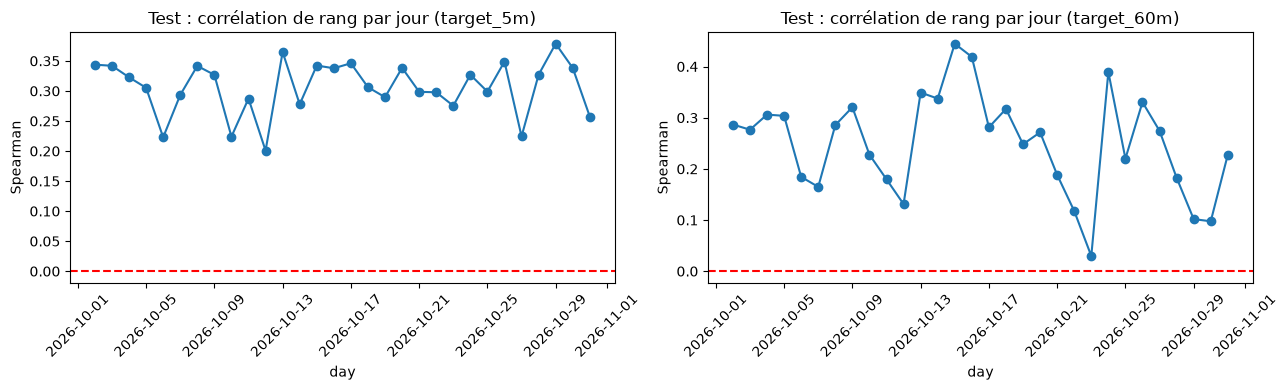

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, target in zip(axes, HORIZONS):
    _, test = final_blocks(df_ctx, target)
    daily = daily_spearman(test, final[target]["y_test"], final[target]["pred_forest"])
    daily.plot(ax=ax, marker="o")
    ax.axhline(0, color="red", ls="--")
    ax.set_title(f"Test : corrélation de rang par jour ({target})")
    ax.set_ylabel("Spearman")
    axes[0].tick_params(axis='x', labelrotation=45)
    axes[1].tick_params(axis='x', labelrotation=45)
plt.tight_layout()
plt.show()

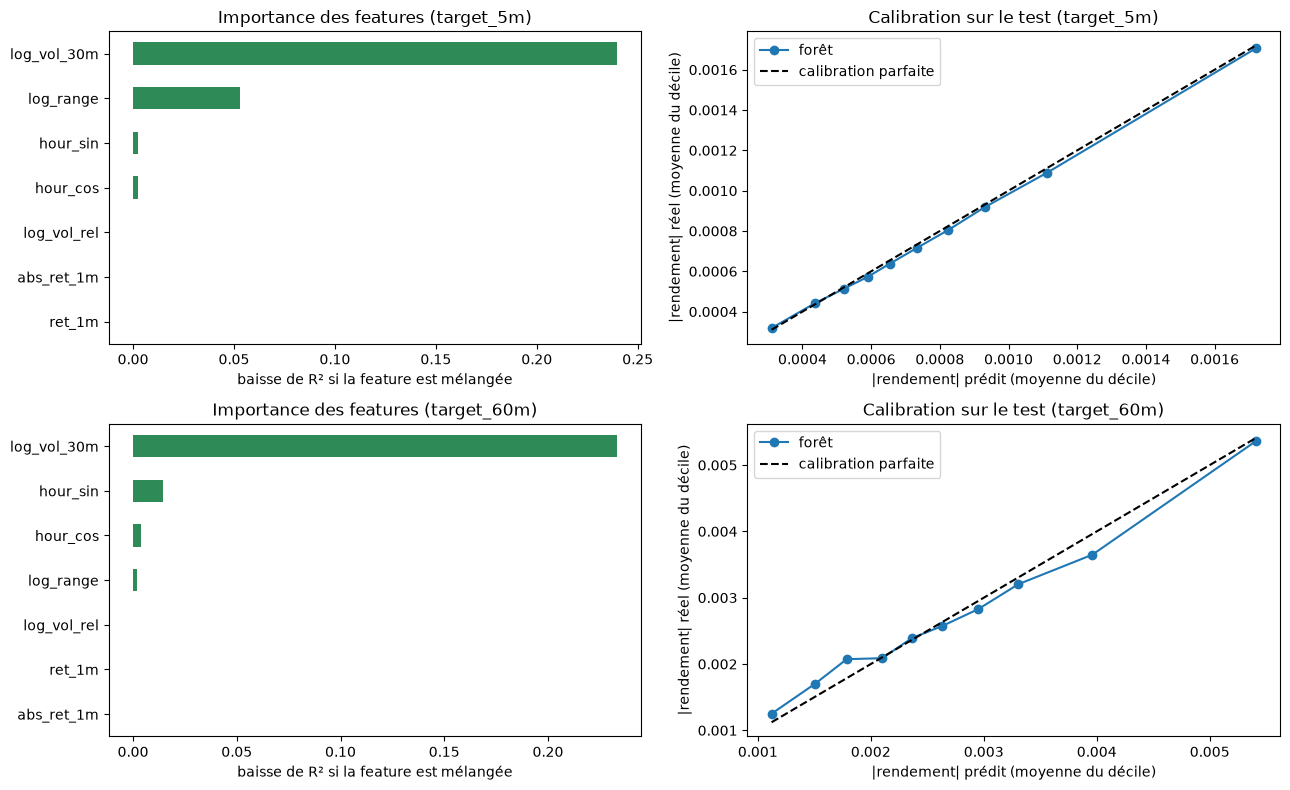

In [34]:
from sklearn.inspection import permutation_importance


def plot_importance_and_calibration(target: str, ax_imp: plt.Axes, ax_cal: plt.Axes) -> None:
    """Trace l'importance des features et la calibration de la forêt sur le test.

    Args:
        target: Colonne cible ("target_5m" ou "target_60m").
        ax_imp: Axe pour l'importance par permutation.
        ax_cal: Axe pour la calibration par décile.

    Returns:
        None. Les graphiques sont dessinés sur les axes fournis.
        L'importance est mesurée sur un sous-échantillon du test (100 000
        lignes) pour limiter le temps de calcul.
    """
    dev, test = final_blocks(df_ctx, target)
    y_dev = dev[target].abs().to_numpy()
    forest = build_models()["random_forest"].fit(dev[FEATURES_VOL], y_dev)

    # Importance par permutation : baisse du R² quand on mélange une feature.
    sample = test.sample(100_000, random_state=0)
    imp = permutation_importance(
        forest, sample[FEATURES_VOL], sample[target].abs(),
        n_repeats=5, random_state=0, n_jobs=-1, scoring="r2")
    pd.Series(imp.importances_mean, index=FEATURES_VOL).sort_values().plot.barh(
        ax=ax_imp, color="seagreen")
    ax_imp.set_title(f"Importance des features ({target})")
    ax_imp.set_xlabel("baisse de R² si la feature est mélangée")

    # Calibration : volatilité réelle moyenne par décile de volatilité prédite.
    pred, y_te = final[target]["pred_forest"], final[target]["y_test"]
    deciles = pd.qcut(pred, 10, duplicates="drop")
    calib = pd.DataFrame({"pred": pred, "real": y_te}).groupby(deciles, observed=True).mean()
    ax_cal.plot(calib["pred"], calib["real"], "o-", label="forêt")
    lim = [calib.to_numpy().min(), calib.to_numpy().max()]
    ax_cal.plot(lim, lim, "k--", label="calibration parfaite")
    ax_cal.set_xlabel("|rendement| prédit (moyenne du décile)")
    ax_cal.set_ylabel("|rendement| réel (moyenne du décile)")
    ax_cal.set_title(f"Calibration sur le test ({target})")
    ax_cal.legend()


fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for i, target in enumerate(HORIZONS):
    plot_importance_and_calibration(target, axes[i, 0], axes[i, 1])
plt.tight_layout()
plt.show()